# Crossdating tree-ring data with dplPy

Crossdating is the step that makes a tree-ring collection usable: it confirms that every ring is assigned to the exact calendar year in which it grew. A single missing or false ring throws off the dating of every older ring by a year, so before any climate or ecological analysis the collection has to be checked ring by ring.

Behind every tool here is one idea, the **leave-one-out master**. To test one series, dplPy averages all the *other* series into a master chronology and correlates the series against it. A correctly dated series tracks the master closely. A misdated segment drifts out of step, and the pattern of that drift shows where and how the dating went wrong.

This notebook walks through the full set of crossdating tools in dplPy:

- reading and detrending a collection
- the mean interseries correlation
- testing each series with `xdate`
- the overview plot
- locating a simulated dating error
- dating a floating (undated) series and rejoining it
- emulating the classic COFECHA program
- batch QA reports
- and `dpl.check`, which screens a collection for data problems that are not dating errors

dplR users will recognize this workflow from `corr.rwl.seg`, `corr.series.seg`, and `ccf.series.rwl`. Every example uses the sample files in `../tests/data/rwl/`, so the notebook runs as-is from the `notebooks/` folder of the repository.

In [1]:
import dplpy as dpl
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

%matplotlib inline
dpl.__version__

'0.8.0'

In [2]:
RWL = "../tests/data/rwl/"   # sample files, relative to the notebooks/ folder

## 1. Reading and detrending a collection

Crossdating compares the *shared* year-to-year signal between trees, so the first step is to remove each series' own biological growth trend. A young tree grows wide rings that narrow with age, and that slow trend is unique to each tree. Left in, it would swamp the common climate signal that crossdating relies on.

Detrending divides each measured series by a smooth curve fitted to it, leaving a dimensionless **ring-width index (RWI)** that hovers around 1.0 and carries the high-frequency signal. This is the same detrending used for standardization (see the detrending guide); here we use a spline, in the spirit of COFECHA's 32-year default.

We start with `ca533`, a bristlecone pine collection from Campito Mountain that ships with both dplR and dplPy.

In [3]:
rwl = dpl.readers(RWL + "ca533.rwl")

ca533.rwl successfully extracted as rwl file with 34 series covering the period from 626 to 1983


In [4]:
dpl.report(rwl)                        # quick overview of the collection

Number of dated series: 34
Number of measurements: 23276
Avg series length: 684.5882
Range: 1358
Span: 626 - 1983
Mean (Std dev) series intercorrelation: 0.631 (0.085)
Mean (Std dev) AR1: 0.7093 (0.0981)
-------------
Years with locally absent rings (zero values) listed by series

      CAM011 (2): 1753 1782
      CAM031 (14): 1497 1500 1523 1533 1540 1542 1545 1578 1579 1580 1655 1668 1670 1681
      CAM032 (7): 1497 1523 1579 1654 1670 1681 1782
      CAM051 (1): 1475
      CAM061 (14): 1497 1523 1542 1545 1547 1579 1654 1655 1668 1670 1672 1782 1858 1960
      CAM062 (14): 1542 1545 1547 1548 1579 1654 1655 1670 1672 1782 1836 1857 1858 1929
      CAM071 (29): 1269 1497 1498 1523 1542 1547 1578 1579 1612 1655 1656 1668 1670 1672 1674 1690 1707 1708 1756 1782 1795 1820 1836 1845 1857 1858 1924 1948 1960
      CAM072 (21): 1218 1497 1498 1523 1533 1538 1542 1545 1546 1547 1571 1579 1580 1590 1654 1655 1668 1670 1672 1675 1690
      CAM081 (2): 1218 1336
      CAM082 (3): 1362 1858 186

,series,first,last,year,mean,median,stdev,skew,kurtosis,gini,ar1
1,CAM011,1530,1983,454,0.440,0.40,0.222,1.029,1.102,0.273,0.696
2,CAM021,1433,1983,551,0.424,0.40,0.185,0.946,1.110,0.237,0.701
3,CAM031,1356,1983,628,0.349,0.29,0.214,0.690,-0.366,0.341,0.808
4,CAM032,1435,1983,549,0.293,0.26,0.163,0.717,0.159,0.309,0.661
5,CAM041,1683,1983,301,0.526,0.53,0.223,0.488,0.098,0.238,0.690
6,CAM042,1538,1983,446,0.439,0.36,0.348,3.678,17.713,0.324,0.880
7,CAM051,1247,1983,737,0.273,0.25,0.140,1.836,6.678,0.262,0.705
8,CAM061,1357,1983,627,0.462,0.47,0.202,-0.111,-0.223,0.247,0.509
9,CAM062,1525,1983,459,0.442,0.45,0.188,-0.266,-0.196,0.240,0.529
10,CAM071,1037,1983,947,0.249,0.25,0.109,0.027,0.022,0.247,0.577


In [5]:
rwi = dpl.detrend(rwl, fit="Spline", plot=False)
rwi.head()                             # detrended indices, one column per series

,CAM011,CAM021,CAM031,CAM032,CAM041,CAM042,CAM051,CAM061,CAM062,CAM071,...,CAM151,CAM152,CAM161,CAM162,CAM171,CAM172,CAM181,CAM191,CAM201,CAM211
Year,,,,,,,,,,,,,,,,,,,,,
626,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.371562
627,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.284366
628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.306488
629,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.416286
630,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.482406


## 2. Mean interseries correlation

The single most useful number for a collection is its **mean interseries correlation**: the average, across all series, of how well each one correlates with the master built from the others. COFECHA prints this as the overall interseries correlation, and a value around 0.5 or higher is typical of a well-dated, climate-sensitive site.

`interseries_corr` takes the **raw** ring widths, not the detrended indices. It prewhitens and normalizes internally, the way COFECHA does.

In [6]:
ic = dpl.interseries_corr(rwl)           # dict: {"mean", "table"}
ic["mean"]                               # collection-wide mean interseries correlation

0.631

In [7]:
ic["table"].head()                     # per-series correlation and p-value

,rho,p_val
series,,
CAM011,0.531,2.766615e-34
CAM021,0.658,4.399694e-69
CAM031,0.545,1.221358e-49
CAM032,0.628,2.033818e-61
CAM041,0.492,7.837035e-20


## 3. Testing each series with `xdate`

`xdate` is the workhorse. It slides a window along each series, correlates each window against the leave-one-out master, and flags the windows that look wrong:

- **flag A** means the window does not correlate significantly with the master, so it is weak or possibly misdated.
- **flag B** means the window correlates *better* at a non-zero lag than at lag 0, the classic signature of a dating shift.

The flag report prints as it runs. The full results come back in a dictionary, including a per-series correlation table and a count of possible problems.

In [8]:
res = dpl.xdate(rwi)                   # prints the flag report as it runs

      Number of dated series      : 34
      Master series               : 626-1983, 1358 yrs
      Total rings in all series   : 23276
      Total dated rings checked   : 22300
      Series intercorrelation     : 0.641
      Avg mean sensitivity        : 0.322
      Segments, possible problems : 18
      Mean length of series       : 684.6

Flags for CAM011
  [B] correlates better at another lag ('best' = that lag; negative = missing ring):
      Segment     best     -10    -9    -8    -7    -6    -5    -4    -3    -2    -1     0    +1    +2    +3    +4    +5    +6    +7    +8    +9   +10
      1900-1949     +6   -0.08 -0.28  0.19 -0.21  0.07 -0.21 -0.22  0.05 -0.20  0.21  0.21 -0.03 -0.00  0.04  0.12 -0.05  0.31  0.23 -0.15  0.05 -0.05

Flags for CAM031
  [B] correlates better at another lag ('best' = that lag; negative = missing ring):
      Segment     best     -10    -9    -8    -7    -6    -5    -4    -3    -2    -1     0    +1    +2    +3    +4    +5    +6    +7    +8    +9   +1

In [9]:
res["n_problems"]                      # number of flagged segments

18

In [10]:
res["overall"].head()                  # each series' correlation with the master

,rho,p_val
CAM011,0.543,2.352082e-36
CAM021,0.694,2.828468e-80
CAM031,0.567,7.189969e-55
CAM032,0.627,4.818971e-61
CAM041,0.483,3.922603e-19


## 4. The crossdating overview plot

`xdate_plot` draws the whole collection at a glance. Each series is a horizontal bar across its calendar extent:

- **green** is the series' full span.
- **blue** is a segment that dates well.
- **red** is a flagged segment to inspect.

A healthy collection is almost all blue. The red segments are where to look next.

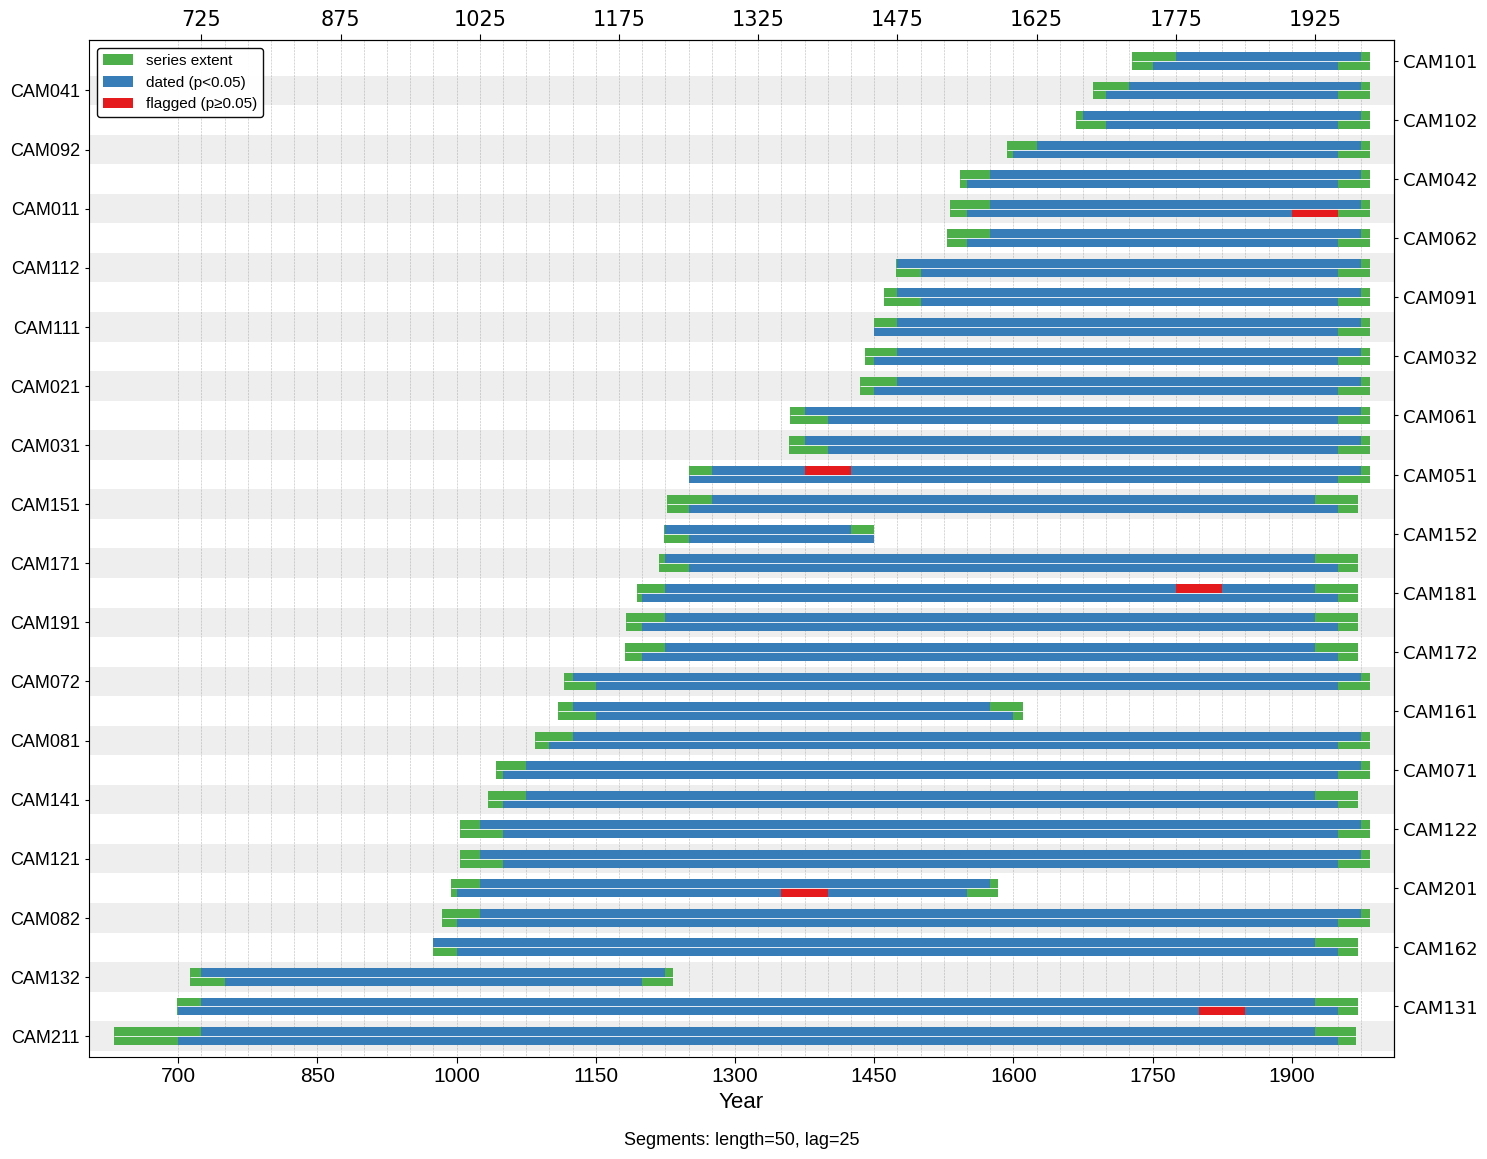

In [11]:
dpl.xdate_plot(rwi, p_val=0.05)
plt.show()

## 5. Locating a dating error

The most common real error is a **missing ring**. In a dry year a tree may grow a ring so thin it was never measured. Every ring *older* than the gap then gets labeled one year too young, and the series slips out of step with the master over its older half.

Following Andy Bunn's dplR crossdating workshop, we simulate exactly that on the `co021` collection. We deliberately corrupt series `644222`: remove its ring for the year **1600**, as if it had been missed while measuring, and prepend an `NaN` so the series keeps its length while every ring older than 1600 shifts a year too young.

In [12]:
co = dpl.readers(RWL + "co021.rwl")

# corrupt one series: drop its 1600 ring and prepend NaN, as if it had been missed
series = "644222"
year = 1600
i = co.index.get_loc(year)             # row position of the ring to drop

miss = co.copy()
col = miss[series].to_numpy()
miss[series] = np.concatenate(([np.nan], np.delete(col, i)))
series, year                           # the corrupted series and the ring's true year

co021.rwl successfully extracted as rwl file with 35 series covering the period from 1176 to 1963


('644222', 1600)

In [13]:
miss_rwi = dpl.detrend(miss, fit="Spline", plot=False)
res_miss = dpl.xdate(miss_rwi)         # the corrupted series now draws flags

      Number of dated series      : 35
      Master series               : 1176-1963, 788 yrs
      Total rings in all series   : 19771
      Total dated rings checked   : 18700
      Series intercorrelation     : 0.871
      Avg mean sensitivity        : 0.604
      Segments, possible problems : 9
      Mean length of series       : 564.9

Flags for 644222
  [B] correlates better at another lag ('best' = that lag; negative = missing ring):
      Segment     best     -10    -9    -8    -7    -6    -5    -4    -3    -2    -1     0    +1    +2    +3    +4    +5    +6    +7    +8    +9   +10
      1350-1399     -1    0.02  0.04 -0.16 -0.06 -0.16  0.03 -0.31 -0.12  0.07  0.68 -0.03  0.09 -0.15  0.17  0.00  0.11 -0.18 -0.03 -0.23 -0.01 -0.04
      1375-1424     -1   -0.28  0.10 -0.41 -0.09 -0.16 -0.02 -0.01  0.27  0.04  0.83 -0.10  0.34 -0.07 -0.05 -0.01 -0.16 -0.28 -0.02 -0.27 -0.07 -0.11
      1400-1449     -1   -0.41 -0.02 -0.32 -0.15 -0.14  0.09  0.08  0.16  0.03  0.77 -0.00  0.31  0.10

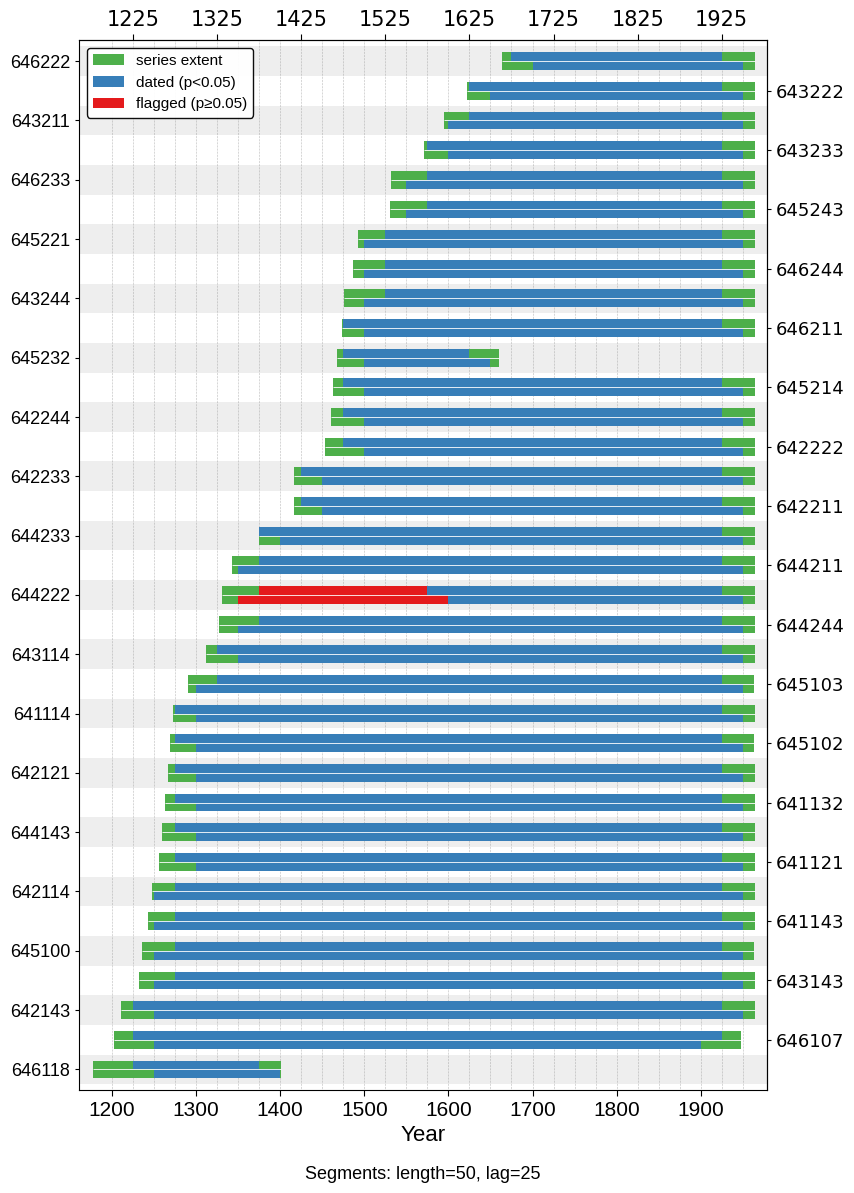

In [14]:
dpl.xdate_plot(miss_rwi)               # the corrupted series reads red over its older half
plt.show()

## 6. Drilling into the flagged series

`series_corr` zooms in on one series. The lag panel is the key part: for each window it shows the lag at which the window best matches the master.

For a missing ring, every window *older* than the gap correlates best at lag +1, while younger windows sit at lag 0. The year where the lag jumps from 0 to +1 is the year the ring was missed. The error is located, not just detected.

NB: negative lags indicate missing rings in the series (as in COFECHA)


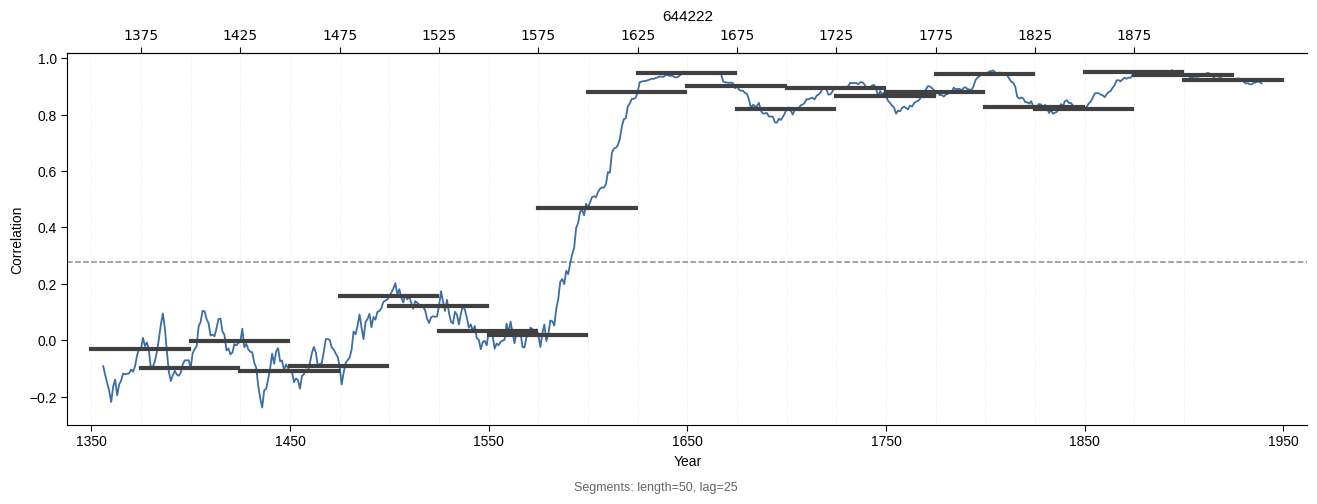

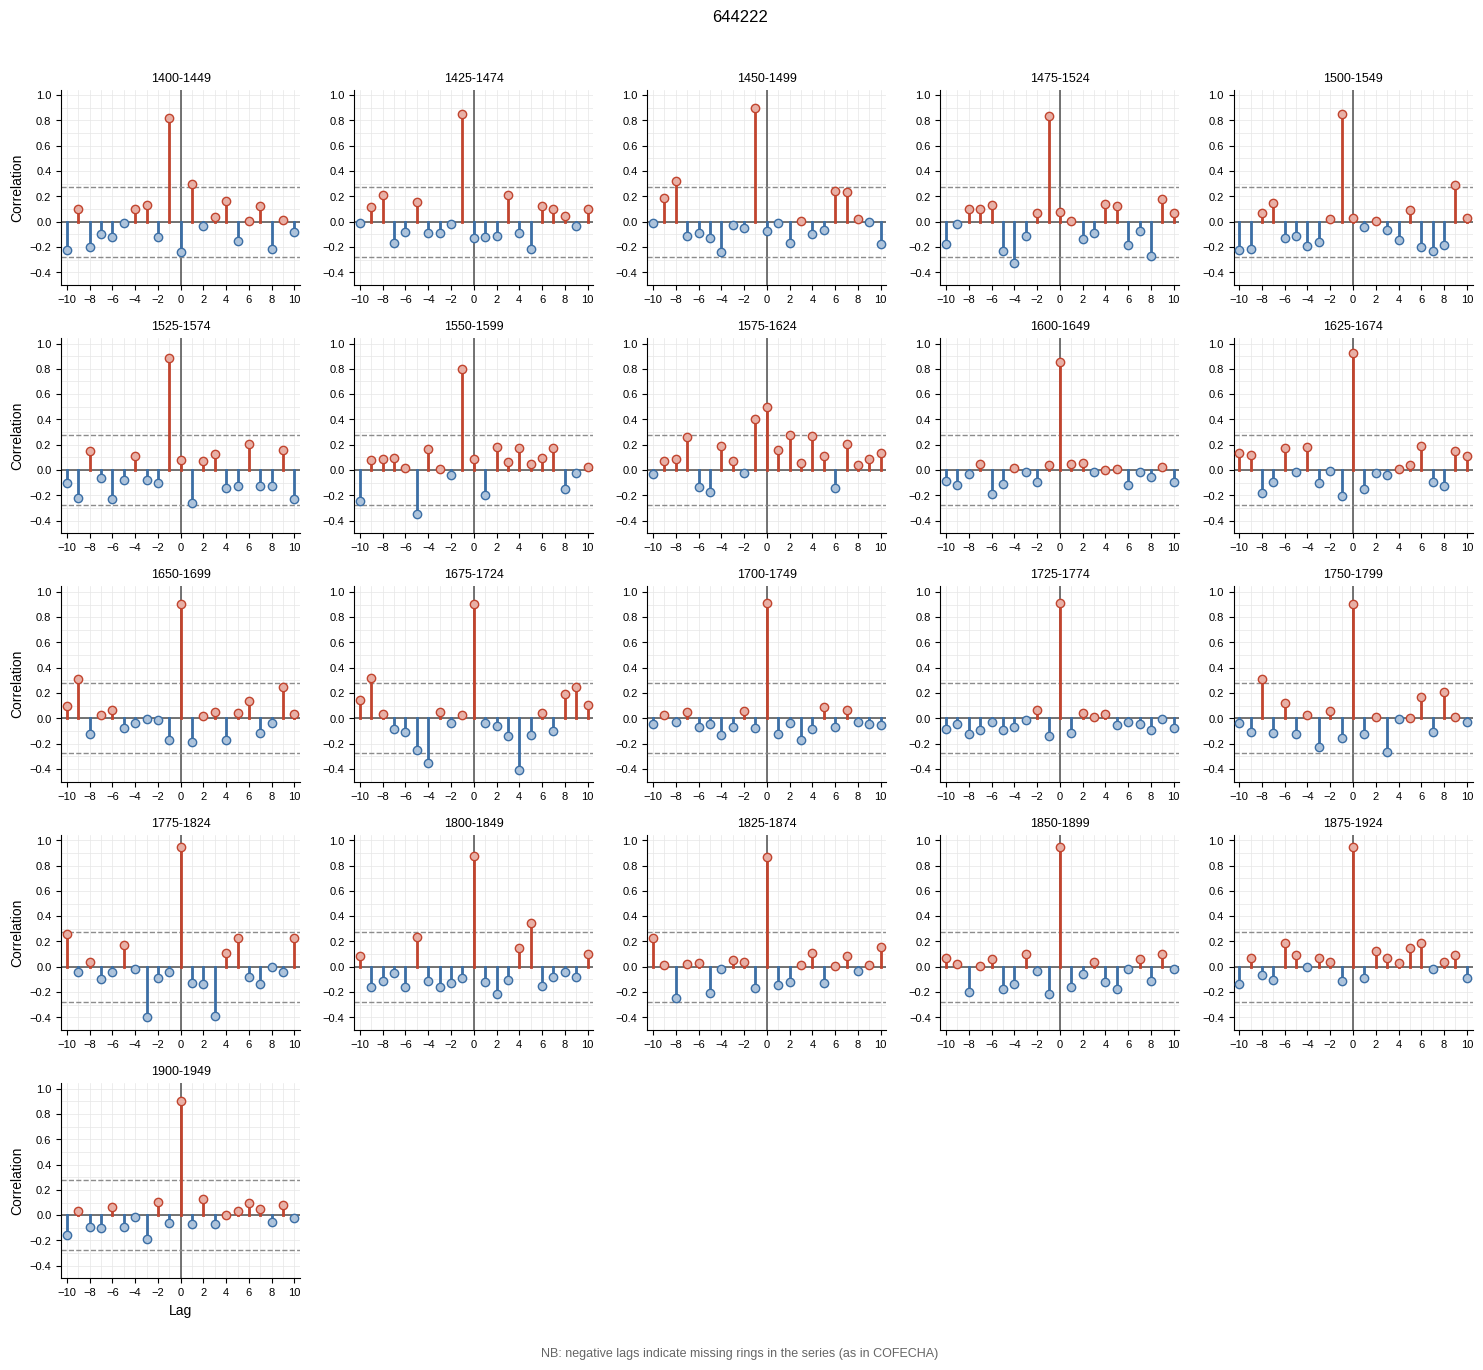

In [15]:
sc_miss = dpl.series_corr(miss_rwi, series, plot=True)
plt.show()

## 7. Dating a floating series

Sometimes a series carries no calendar dates at all, such as a beam from an old building or a subfossil log. Given a dated reference collection, `xdate_floater` finds where the floating series belongs in time.

Here we take one series from `ca533`, throw away its dates, and recover them.

Reference master years: 631 to 1983 (1353)
Floating series length: 551 (transform 'pw' -> 545)
Minimum overlap for search: 50



Best match for 'CAM021': 1433 to 1983  (t = 20.34, r = 0.658, eff_df = 545, p_bonf = 6.94e-66, 1/p = >1 million, IF = >1000, overlap n = 545)


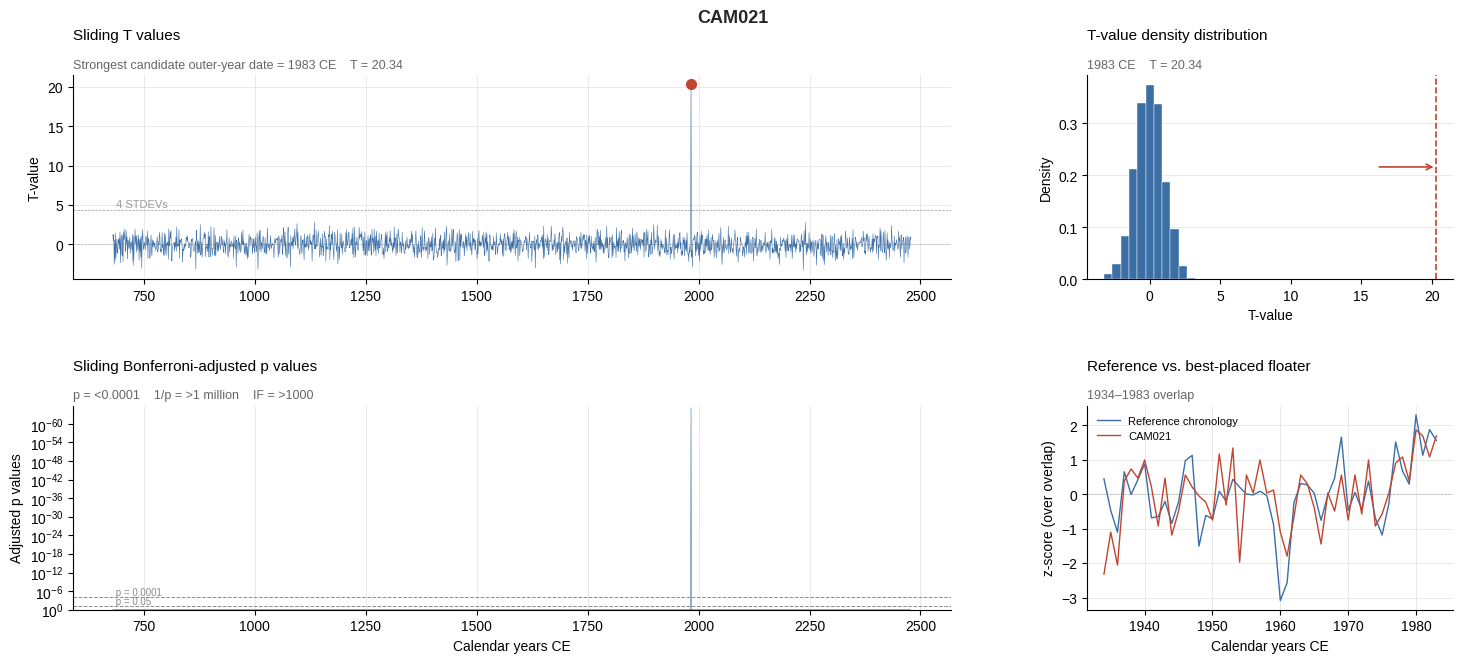

In [16]:
floating = rwl["CAM021"].dropna().values     # just the ring values, undated
reference = rwl.drop(columns=["CAM021"])      # the rest of the collection as reference

fl = dpl.xdate_floater(reference, floating, series_name="CAM021", plot=True, return_rwl=True)
plt.show()

In [17]:
fl["best"]                             # the recovered calendar placement

{'min_year': 1433,
 'max_year': 1983,
 'r': 0.6575472355491244,
 't': 20.337143327658065,
 'eff_df': 544.990930993626,
 'p_bonf': 6.93775874208215e-66,
 'one_over_p': 1.4413876832215724e+65,
 'isolation_factor': 5.386473277333847e+65,
 'n': 545,
 'date_warning': None}

### Rejoining the placed series

With `return_rwl=True`, `xdate_floater` hands back the floater already dated at its best-fit years as `fl["placed"]`. We pass that straight to `combine_rwl`, which merges it into the reference collection on the union of their years, exactly as dplR's `combine.rwl` does. Because the placement is correct, the recovered `CAM021` lands back on its original years and the rejoined collection matches the one we started with.

(`xdate_floater` also returns `fl["combined"]`, the same rejoin done for you, when you do not need the two pieces separately.)

In [18]:
placed = fl["placed"] # the floater, dated at its best-fit years

rejoined = dpl.combine_rwl(reference, placed) # use combine_rwl to join two DataFrames along their year index
rejoined.shape # size of the reference plus the replaced series - back to the whole collection

(1358, 34)

In [19]:
# the recovered series lands back on its original years
recovered = rejoined["CAM021"].dropna().values
original = rwl["CAM021"].dropna().values
np.array_equal(recovered, original)  # if True the placement is exact

True

## 8. Emulating COFECHA

COFECHA (Holmes, 1983) is the Fortran program that has been the standard crossdating check for decades. `preset="COFECHA"` reproduces its exact recipe: a 32-year spline detrend, autoregressive prewhitening using the Burg method, an arithmetic z-scored master, Pearson instead of Spearman correlation, and COFECHA's segment anchoring and critical value.

Unlike the default path, the preset expects to take the **raw** ring widths and detrends them itself, just as the COFECHA Fortran program did, so there is no need to call `detrend` first.

In [20]:
cof = dpl.xdate(rwl, preset="COFECHA")  # raw frame; the preset detrends internally

      Number of dated series      : 34
      Master series               : 626-1983, 1358 yrs
      Total rings in all series   : 23276
      Total dated rings checked   : 23227
      Series intercorrelation     : 0.669
      Avg mean sensitivity        : 0.316
      Segments, possible problems : 15
      Mean length of series       : 684.6

Flags for CAM011
  [A] not significant as dated ('best' = lag of highest correlation):
      Segment     best     -10    -9    -8    -7    -6    -5    -4    -3    -2    -1     0    +1    +2    +3    +4    +5    +6    +7    +8    +9   +10
      1900-1949     +0    0.03 -0.25  0.17 -0.04  0.08 -0.22 -0.23 -0.02 -0.20  0.07  0.31 -0.23 -0.04 -0.06 -0.00 -0.01  0.22  0.26 -0.14  0.08 -0.13
  [B] correlates better at another lag ('best' = that lag; negative = missing ring):
      Segment     best     -10    -9    -8    -7    -6    -5    -4    -3    -2    -1     0    +1    +2    +3    +4    +5    +6    +7    +8    +9   +10
      1934-1983     -1   -0.02 

In [21]:
cof["n_problems"]                       # COFECHA-style count of possible problems

15

## 9. Batch QA reports

`xdate_report` runs the whole crossdating check on a file and produces a COFECHA-style text report, built for screening many files at once. It accepts a file path or a collection already read into memory.

`output=` controls where the report goes: `"screen"` prints it, `"file"` writes a `.txt`, and `"both"` (the default) does both. We use `"screen"` here so the notebook does not leave files behind.

In [22]:
rep = dpl.xdate_report(RWL + "ca533.rwl", output="screen", preset="COFECHA") # call the report on a file not yet in memory

ca533.rwl successfully extracted as rwl file with 34 series covering the period from 626 to 1983



COFECHA-style output, reproduced with dplPy 0.8.0 preset="COFECHA" on 15Oct26


      Measurement file name  : ca533.rwl
      Beginning year         : 626
      Ending year            : 1983

      Series intercorrelation: .669
      Avg mean sensitivity   : .316
      Avg standard deviation : .188
      Avg autocorrelation    : .717
      Number dated series    : 34
      Segment length tested  : 50

      Number problem segments: 18
      Pct problem segments   : 1.94


 PART 5:  CORRELATION OF SERIES BY SEGMENTS: 
-----------------------------------------------------------------------------------------------------------------------------------
Correlations of  50-year dated segments, lagged  25 years
Flags:  A = correlation under .3281 but highest as dated;  B = correlation higher at other than dated position
        critical value .3281 for the 50-year window, from pcrit = 0.01, one tailed

 Seq Series  Time_span     625  650  675  700  725  750  775  800  825  850  875  900  925

In [23]:
nm046 = dpl.readers(RWL + "nm046.rwl")
rep2 = dpl.xdate_report(nm046, name="nm046", output="screen")   # or, call a collection already in memory

nm046.rwl successfully extracted as rwl file with 8 series covering the period from 1681 to 1969

COFECHA-style output, reproduced with dplPy 0.8.0 on 15Oct26


      Measurement file name  : nm046
      Beginning year         : 1681
      Ending year            : 1969

      Series intercorrelation: .821
      Avg mean sensitivity   : .477
      Avg standard deviation : 1.076
      Avg autocorrelation    : .579
      Number dated series    : 8
      Segment length tested  : 50

      Number problem segments: 0
      Pct problem segments   : 0.00


 PART 5:  CORRELATION OF SERIES BY SEGMENTS: 
-----------------------------------------------------------------------------------------------------------------------------------
Correlations of  50-year dated segments, lagged  25 years
Flags:  A = correlation not significant but highest as dated;  B = correlation higher at other than dated position
        critical value from pcrit = 0.05, one tailed

 Seq Series  Time_span    1700 1725 1750

## 10. Integrity checks with `dpl.check`

Crossdating asks whether every ring is on its correct year. `dpl.check` asks a different question: does the data make sense at all? It screens a collection for problems that are *not* dating errors and returns them as a table of findings, one row per problem.

Each finding carries:

- **series** -- the series it concerns, blank for a whole-collection or file-level finding. In crossdating you think series-first: which cores are fine and which need a look.
- **check** -- a stable id for the kind of problem, matching dplR's `rwl.check` ids, such as `RWL_INTERNAL_NA` or `RWL_SERIES_OUTLIER`.
- **severity** -- `error`, `warning`, or `note`, so you can triage at a glance.
- **group** -- the family the check belongs to: structure, series, values, zeros, crossdating, file, or provenance.
- **year_from**, **year_to**, **n** -- where the problem sits in the series and how many rings it spans.
- **value** -- a number attached to the finding, such as a correlation or a lag.
- **message** -- a plain-English description.

The checks cover missing values inside a series, duplicated cores, a constant value used as a not-measured placeholder (a real ITRDB hazard, like someone entering `1` for a ring that was never measured), implausible means or units, locally absent rings, file-format defects, and the crossdating screen itself.

`check` and the dating tools complement each other. Where `xdate` and `series_corr` *locate* a dating error, `check` flags the same series from a different angle. Run it on the collection with the simulated missing ring, and the corrupted series turns up as a poor-fit crossdating outlier.

In [24]:
findings = dpl.check(miss, file="co021 (simulated error)")
findings[findings["group"] == "crossdating"][["series", "check", "severity", "message"]]

,series,check,severity,message
0,644222,RWL_SERIES_OUTLIER,warning,correlates with the collection at r = 0.494 wh...


In [25]:
clean = dpl.check(RWL + "ca533.rwl")   # a well-formed file
clean[["series", "check", "severity", "year_from", "year_to", "message"]].head(8)

,series,check,severity,year_from,year_to,message
0,CAM031,RWL_CONSECUTIVE_ZERO,note,1578.0,1580.0,"3 consecutive absent rings, 1578-1580"
1,CAM061,RWL_CONSECUTIVE_ZERO,note,1654.0,1655.0,"2 consecutive absent rings, 1654-1655"
2,CAM062,RWL_CONSECUTIVE_ZERO,note,1547.0,1548.0,"2 consecutive absent rings, 1547-1548"
3,CAM062,RWL_CONSECUTIVE_ZERO,note,1654.0,1655.0,"2 consecutive absent rings, 1654-1655"
4,CAM062,RWL_CONSECUTIVE_ZERO,note,1857.0,1858.0,"2 consecutive absent rings, 1857-1858"
5,CAM071,RWL_CONSECUTIVE_ZERO,note,1497.0,1498.0,"2 consecutive absent rings, 1497-1498"
6,CAM071,RWL_CONSECUTIVE_ZERO,note,1578.0,1579.0,"2 consecutive absent rings, 1578-1579"
7,CAM071,RWL_CONSECUTIVE_ZERO,note,1655.0,1656.0,"2 consecutive absent rings, 1655-1656"


In [26]:
clean.groupby(["severity", "check"]).size()   # how many of each kind, across the file

severity  check               
note      RWL_CONSECUTIVE_ZERO    22
          RWL_LOW_DEPTH            1
          RWL_ZERO_RING            1
dtype: int64

## Where to go next

That is the full crossdating toolkit: a collection-wide number (`interseries_corr`), a per-series test (`xdate`), a visual overview (`xdate_plot`), a per-series drill-down (`series_corr`), floating-series placement and rejoining (`xdate_floater`, `combine_rwl`), COFECHA emulation (`preset="COFECHA"`), batch reports (`xdate_report`), and a data-integrity screen (`dpl.check`).

- For the detrending step behind the indices, see the [detrending and standardization guide](https://opendendro.github.io/dplPy/guide/detrending-standardization/).
- For how dplPy's crossdating compares with COFECHA and dplR, see the [crossdating background note](https://opendendro.github.io/dplPy/background/crossdating-methods/).
- For building chronologies from a crossdated, detrended collection, see the [chronologies guide](https://opendendro.github.io/dplPy/guide/chronologies/).